# Pipeline Data + Model LSTM (BTC, ETH, SOL, multi-horizon)

**Bagian A — Pipeline Data**: ekstraksi, konversi, dan preprocessing data BTC/ETH/SOL dari Indodax dan Binance.

**Bagian B — Model LSTM**: 5 model terpisah per aset (h = 1, 3, 7, 14, 30 hari), evaluasi
(MAE, RMSE, MAPE, R2), dan prediksi 5 titik ke depan per horizon.

**Bagian C — Integrasi Markowitz**: konversi prediksi harga ke expected return, matriks
covariance dari data historis, dan optimasi bobot portofolio (maksimasi Sharpe Ratio,
batas minimum 20% per aset).

In [1]:
!pip install ccxt scikit-learn joblib tensorflow matplotlib -q

ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)
ERROR: No matching distribution found for tensorflow


## Konfigurasi

In [2]:
import os
import ccxt
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv1D, Add, Activation, GlobalAveragePooling1D

In [3]:
ASSETS = ["BTC", "ETH", "SOL"]
HORIZONS = [1, 3, 7, 14, 30]
LIMIT = 1000

RAW_DIR, MERGED_DIR, PROCESSED_DIR, SCALER_DIR = "data/raw", "data/merged", "data/processed", "models"
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15

FEATURE_COLS = [
    "Open_indodax", "High_indodax", "Low_indodax", "Close_indodax", "Volume_indodax",
    "Open_binance", "High_binance", "Low_binance", "Close_binance", "Volume_binance",
]

WINDOW_SIZE = 30
EPOCHS = 100
BATCH_SIZE = 8
PATIENCE = 15

for d in [RAW_DIR, MERGED_DIR, PROCESSED_DIR, SCALER_DIR]:
    os.makedirs(d, exist_ok=True)

## Bagian A — Pipeline Data

### Fungsi bantu

In [4]:
def fetch_ohlcv(exchange, symbol, limit=LIMIT):
    """Ambil OHLCV harian untuk satu simbol, kembalikan DataFrame rapi."""
    ohlcv = exchange.fetch_ohlcv(symbol, timeframe="1d", limit=limit)
    df = pd.DataFrame(ohlcv, columns=["Timestamp", "Open", "High", "Low", "Close", "Volume"])
    df["Tanggal"] = pd.to_datetime(df["Timestamp"], unit="ms")
    return df[["Tanggal", "Open", "High", "Low", "Close", "Volume"]]


def convert_binance_to_idr(df_binance, df_kurs):
    """Konversi harga/volume USDT -> IDR memakai kurs USDT/IDR harian."""
    df = df_binance.merge(df_kurs[["Tanggal", "Close"]].rename(columns={"Close": "Kurs_USDT_IDR"}), on="Tanggal", how="left")
    for col in ["Open", "High", "Low", "Close"]:
        df[f"{col}_IDR"] = df[col] * df["Kurs_USDT_IDR"]
    df["Volume_IDR"] = df["Volume"] * df["Close_IDR"]
    df_idr = df[["Tanggal", "Open_IDR", "High_IDR", "Low_IDR", "Close_IDR", "Volume_IDR"]].copy()
    df_idr.columns = ["Tanggal", "Open", "High", "Low", "Close", "Volume"]
    df_idr["Tanggal"] = pd.to_datetime(df_idr["Tanggal"])
    return df_idr


def add_targets(df, close_col="Close_indodax", horizons=HORIZONS):
    """Tambah Target_hd = Close t+h, buang ekor tanpa target."""
    df = df.sort_values("Tanggal").reset_index(drop=True)
    for h in horizons:
        df[f"Target_{h}d"] = df[close_col].shift(-h)
    return df.iloc[:-max(horizons)].reset_index(drop=True)


def chronological_split(df, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO):
    """Bagi berurutan waktu jadi train, val, test."""
    train_end = int(len(df) * train_ratio)
    val_end = train_end + int(len(df) * val_ratio)
    return df.iloc[:train_end].reset_index(drop=True), df.iloc[train_end:val_end].reset_index(drop=True), df.iloc[val_end:].reset_index(drop=True)


def fit_scale(train, val, test, feature_cols=FEATURE_COLS):
    """Fit MinMaxScaler hanya dari train (kolom fitur saja), lalu transform ketiganya.
    Target_hd SENGAJA tidak ikut di-scale di sini -- scaling target dilakukan terpisah
    per horizon di train_lstm_for_horizon(), supaya tiap horizon punya skala targetnya sendiri."""
    scaler = MinMaxScaler(feature_range=(0, 1)).fit(train[feature_cols])
    for split in (train, val, test):
        split[feature_cols] = scaler.transform(split[feature_cols])
    return train, val, test, scaler

### Tahap 1–2: Ekstraksi, Konversi, Penggabungan

In [5]:
# --- Ekstraksi Indodax + Binance + simpan raw ---
indodax, binance, raw_data = ccxt.indodax(), ccxt.binance(), {}

def safe_fetch(exchange, symbol, key):
    try:
        raw_data[key] = fetch_ohlcv(exchange, symbol)
        print(f"OK  : {symbol} dari {exchange.id} ({len(raw_data[key])} baris)")
    except Exception as e:
        print(f"GAGAL: {symbol} dari {exchange.id} -> {e}")

safe_fetch(indodax, "USDT/IDR", "USDT_IDR")
for asset in ASSETS:
    safe_fetch(indodax, f"{asset}/IDR", f"indodax_{asset}")
for asset in ASSETS:
    safe_fetch(binance, f"{asset}/USDT", f"binance_{asset}")

for name, df in raw_data.items():
    path = os.path.join(RAW_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    print(f"Tersimpan: {path} ({df['Tanggal'].min().date()} s/d {df['Tanggal'].max().date()})")

OK  : USDT/IDR dari indodax (1000 baris)
OK  : BTC/IDR dari indodax (1000 baris)
OK  : ETH/IDR dari indodax (1000 baris)
OK  : SOL/IDR dari indodax (1000 baris)
OK  : BTC/USDT dari binance (1000 baris)
OK  : ETH/USDT dari binance (1000 baris)
OK  : SOL/USDT dari binance (1000 baris)
Tersimpan: data/raw\USDT_IDR.csv (2024-01-23 s/d 2026-10-18)
Tersimpan: data/raw\indodax_BTC.csv (2024-01-23 s/d 2026-10-18)
Tersimpan: data/raw\indodax_ETH.csv (2024-01-23 s/d 2026-10-18)
Tersimpan: data/raw\indodax_SOL.csv (2024-01-23 s/d 2026-10-18)
Tersimpan: data/raw\binance_BTC.csv (2024-01-23 s/d 2026-10-18)
Tersimpan: data/raw\binance_ETH.csv (2024-01-23 s/d 2026-10-18)
Tersimpan: data/raw\binance_SOL.csv (2024-01-23 s/d 2026-10-18)


In [6]:
# --- Merge Indodax + Binance (Binance dikonversi ke IDR dulu) ---
merged_data = {}
for asset in ASSETS:
    try:
        df_merged = pd.merge(raw_data[f"indodax_{asset}"], convert_binance_to_idr(raw_data[f"binance_{asset}"], raw_data["USDT_IDR"]), on="Tanggal", how="inner", suffixes=("_indodax", "_binance"))
        merged_data[asset] = df_merged
        path = os.path.join(MERGED_DIR, f"{asset}_merged.csv")
        df_merged.to_csv(path, index=False)
        print(f"Tersimpan: {path} ({len(df_merged)} baris setelah inner join tanggal)")
    except KeyError as e:
        print(f"[PERINGATAN] Lewati {asset}, data mentah belum lengkap: {e}")

merged_data["BTC"].tail()

Tersimpan: data/merged\BTC_merged.csv (1000 baris setelah inner join tanggal)
Tersimpan: data/merged\ETH_merged.csv (1000 baris setelah inner join tanggal)
Tersimpan: data/merged\SOL_merged.csv (1000 baris setelah inner join tanggal)


,Tanggal,Open_indodax,High_indodax,Low_indodax,Close_indodax,Volume_indodax,Open_binance,High_binance,Low_binance,Close_binance,Volume_binance
995,2026-10-14,1.485486e+09,1.499177e+09,1.462500e+09,1.464206e+09,14.690354,1.489557e+09,1.507068e+09,1.458670e+09,1.462925e+09,2.678260e+13
996,2026-10-15,1.464084e+09,1.476731e+09,1.435965e+09,1.469825e+09,26.711489,1.460229e+09,1.477253e+09,1.426585e+09,1.470310e+09,3.317483e+13
997,2026-10-16,1.469203e+09,1.485720e+09,1.454489e+09,1.465234e+09,11.653001,1.475492e+09,1.487958e+09,1.449718e+09,1.464185e+09,2.160252e+13
998,2026-10-17,1.465232e+09,1.465964e+09,1.450279e+09,1.458683e+09,6.836071,1.461741e+09,1.464501e+09,1.447480e+09,1.459505e+09,1.027327e+13
999,2026-10-18,1.458683e+09,1.473687e+09,1.455000e+09,1.455000e+09,5.401448,1.459749e+09,1.474159e+09,1.451023e+09,1.452050e+09,8.442091e+12


### Tahap 3: Target, Split Kronologis, Scaling

In [7]:
# --- Target + split kronologis + scaling + simpan ---
processed_data = {}
for asset in ASSETS:
    if asset not in merged_data:
        print(f"[PERINGATAN] Lewati {asset}, data merged belum ada")
        continue
    train, val, test, scaler = fit_scale(*chronological_split(add_targets(merged_data[asset])))
    processed_data[asset] = {"train": train, "val": val, "test": test}
    for name, split_df in [("train", train), ("val", val), ("test", test)]:
        out_path = os.path.join(PROCESSED_DIR, f"{asset}_{name}.csv")
        split_df.to_csv(out_path, index=False)
        print(f"Tersimpan: {out_path} ({len(split_df)} baris)")
    scaler_path = os.path.join(SCALER_DIR, f"scaler_{asset}.pkl")
    joblib.dump(scaler, scaler_path)
    print(f"Tersimpan: {scaler_path}")

processed_data["BTC"]["train"].head()

Tersimpan: data/processed\BTC_train.csv (679 baris)
Tersimpan: data/processed\BTC_val.csv (145 baris)
Tersimpan: data/processed\BTC_test.csv (146 baris)
Tersimpan: models\scaler_BTC.pkl
Tersimpan: data/processed\ETH_train.csv (679 baris)
Tersimpan: data/processed\ETH_val.csv (145 baris)
Tersimpan: data/processed\ETH_test.csv (146 baris)
Tersimpan: models\scaler_ETH.pkl
Tersimpan: data/processed\SOL_train.csv (679 baris)
Tersimpan: data/processed\SOL_val.csv (145 baris)
Tersimpan: data/processed\SOL_test.csv (146 baris)
Tersimpan: models\scaler_SOL.pkl


,Tanggal,Open_indodax,High_indodax,Low_indodax,Close_indodax,Volume_indodax,Open_binance,High_binance,Low_binance,Close_binance,Volume_binance,Target_1d,Target_3d,Target_7d,Target_14d,Target_30d
0,2024-01-23,0.000000,0.000000,0.000000,0.000000,0.214772,0.000000,0.000000,0.000000,0.000000,0.185302,630999000.0,662491000.0,678264000.0,676375000.0,802994000.0
1,2024-01-24,0.004222,0.003217,0.012451,0.003656,0.108136,0.004797,0.005339,0.011425,0.003322,0.115577,631221000.0,665771000.0,674232000.0,689641000.0,795199000.0
2,2024-01-25,0.006496,0.004596,0.014854,0.003810,0.068649,0.008737,0.004527,0.014077,0.003913,0.084089,662491000.0,665986000.0,677556000.0,706000000.0,806906000.0
3,2024-01-26,0.006793,0.025512,0.017758,0.025515,0.132111,0.007425,0.025611,0.017106,0.024382,0.155253,665771000.0,678874000.0,679171000.0,735480000.0,809976000.0
4,2024-01-27,0.028433,0.024929,0.035174,0.027792,0.076762,0.028322,0.025856,0.035169,0.028404,0.030865,665986000.0,678264000.0,676010000.0,745572000.0,848100000.0


## Bagian B — Model LSTM (BTC, ETH, SOL, multi-horizon)

### Fungsi bantu

In [8]:
def create_sequences(df, feature_cols, target_col, window_size=WINDOW_SIZE):
    """Bentuk sequence (X) dari fitur dan target (y) dari kolom Target_hd pada hari terakhir tiap window."""
    values = df[feature_cols].values
    targets = df[target_col].values
    X, y = [], []
    for i in range(len(df) - window_size + 1):
        X.append(values[i:i + window_size])
        y.append(targets[i + window_size - 1])  # target sejajar dengan hari terakhir window
    return np.array(X), np.array(y)


def build_model(window_size, n_features):
    inputs = Input(shape=(window_size, n_features))
    x = LSTM(64)(inputs)
    x = Dropout(0.2)(x)
    x = Dense(32, activation="relu")(x)
    outputs = Dense(1)(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.0005), loss="mse")
    return model


def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

### Training per horizon

In [9]:
def train_lstm_for_horizon(asset, asset_data, horizon, feature_cols=FEATURE_COLS, window_size=WINDOW_SIZE):
    """Latih satu model LSTM untuk satu horizon tertentu, kembalikan model + metrik evaluasi."""
    target_col = f"Target_{horizon}d"

    X_train, y_train = create_sequences(asset_data["train"], feature_cols, target_col, window_size)
    X_val, y_val = create_sequences(asset_data["val"], feature_cols, target_col, window_size)
    X_test, y_test = create_sequences(asset_data["test"], feature_cols, target_col, window_size)

    # Scaler khusus target, fit HANYA dari target data latih
    target_scaler = MinMaxScaler(feature_range=(0, 1))
    y_train_scaled = target_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
    y_val_scaled = target_scaler.transform(y_val.reshape(-1, 1)).flatten()

    print(f"\n=== Horizon {horizon} hari ===")
    print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

    model = build_model(window_size, n_features=len(feature_cols))
    early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)

    model.fit(
        X_train, y_train_scaled,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val_scaled),
        callbacks=[early_stop], verbose=0,
    )

    predictions_scaled = model.predict(X_test, verbose=0).flatten()
    predictions = target_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()

    metrics = {
        "Horizon": f"{horizon}d",
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAPE": mean_absolute_percentage_error(y_test, predictions),
        "R2": r2_score(y_test, predictions),
    }

    model_path = os.path.join(SCALER_DIR, f"{asset}_LSTM_h{horizon}.keras")
    model.save(model_path)

    target_scaler_path = os.path.join(SCALER_DIR, f"target_scaler_{asset}_h{horizon}.pkl")
    joblib.dump(target_scaler, target_scaler_path)

    print(f"Tersimpan: {model_path}, {target_scaler_path}")

    return model, metrics, predictions, y_test, target_scaler

In [10]:
# --- Latih 5 model LSTM untuk BTC, satu per horizon ---
btc_data = processed_data["BTC"]

lstm_models = {}
lstm_target_scalers = {}
lstm_metrics = []

for h in HORIZONS:
    model, metrics, predictions, y_test, target_scaler = train_lstm_for_horizon("BTC", btc_data, h)
    lstm_models[h] = model
    lstm_target_scalers[h] = target_scaler
    lstm_metrics.append(metrics)

metrics_df = pd.DataFrame(lstm_metrics)
metrics_df


=== Horizon 1 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_LSTM_h1.keras, models\target_scaler_BTC_h1.pkl

=== Horizon 3 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_LSTM_h3.keras, models\target_scaler_BTC_h3.pkl

=== Horizon 7 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_LSTM_h7.keras, models\target_scaler_BTC_h7.pkl

=== Horizon 14 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_LSTM_h14.keras, models\target_scaler_BTC_h14.pkl

=== Horizon 30 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_LSTM_h30.keras, models\target_scaler_BTC_h30.pkl


,Horizon,MAE,RMSE,MAPE,R2
0,1d,2.125694e+07,3.185804e+07,1.742466,0.917196
1,3d,4.061503e+07,6.088504e+07,3.276728,0.720312
2,7d,6.565741e+07,9.351620e+07,5.274715,0.452192
3,14d,8.423512e+07,1.126480e+08,6.500072,0.366904
4,30d,1.226266e+08,1.448472e+08,9.465481,0.151649


In [11]:
def predict_future(asset, models_dict, target_scalers_dict, horizons=HORIZONS, feature_cols=FEATURE_COLS, window_size=WINDOW_SIZE):
    df_full = merged_data[asset].sort_values("Tanggal").reset_index(drop=True)
    scaler = joblib.load(os.path.join(SCALER_DIR, f"scaler_{asset}.pkl"))

    last_window = df_full[feature_cols].values[-window_size:]
    last_window_scaled = scaler.transform(last_window)
    X_future = last_window_scaled.reshape(1, window_size, len(feature_cols))

    last_date = df_full["Tanggal"].iloc[-1]
    last_close = df_full["Close_indodax"].iloc[-1]

    results = []
    for h in horizons:
        pred_scaled = models_dict[h].predict(X_future, verbose=0).flatten()[0]
        pred_price = target_scalers_dict[h].inverse_transform([[pred_scaled]])[0][0]
        target_date = last_date + pd.Timedelta(days=h)
        results.append({
            "Horizon": f"{h} hari",
            "Tanggal Prediksi": target_date.date(),
            "Harga Terakhir Diketahui": f"Rp{last_close:,.0f}",
            "Prediksi Harga": f"Rp{pred_price:,.0f}",
        })

    return pd.DataFrame(results)


future_btc = predict_future("BTC", lstm_models, lstm_target_scalers)
future_btc

c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


,Horizon,Tanggal Prediksi,Harga Terakhir Diketahui,Prediksi Harga
0,1 hari,2026-10-19,"Rp1,455,000,000","Rp1,444,503,587"
1,3 hari,2026-10-21,"Rp1,455,000,000","Rp1,450,691,961"
2,7 hari,2026-10-25,"Rp1,455,000,000","Rp1,454,906,339"
3,14 hari,2026-11-01,"Rp1,455,000,000","Rp1,421,728,339"
4,30 hari,2026-11-17,"Rp1,455,000,000","Rp1,460,799,374"


### Grafik Historis vs Prediksi (5 titik)

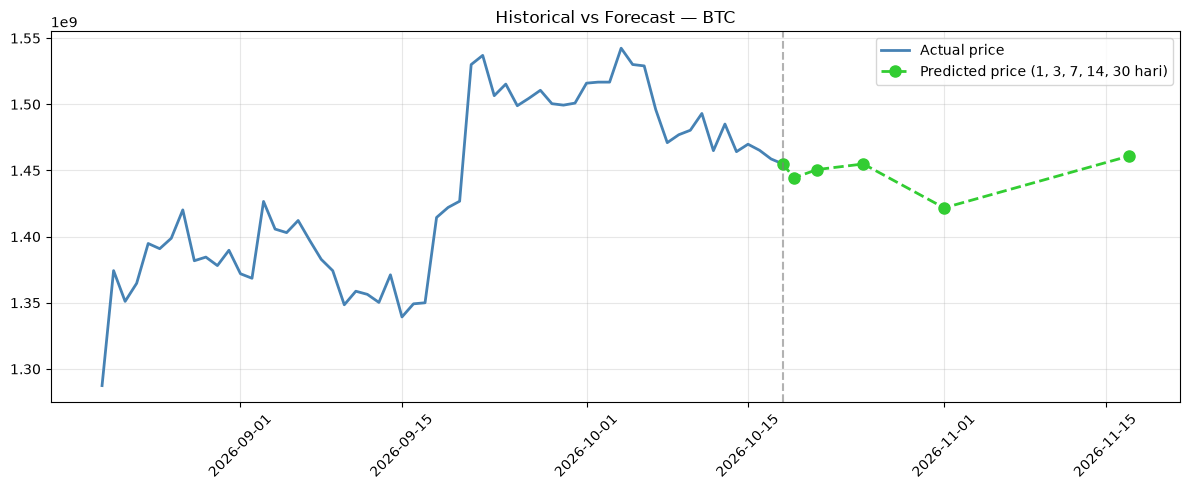

In [12]:
def plot_historical_vs_points(asset, future_df, n_historical_days=60):
    df_full = merged_data[asset].sort_values("Tanggal").reset_index(drop=True)
    historical = df_full[["Tanggal", "Close_indodax"]].tail(n_historical_days)

    last_date = df_full["Tanggal"].iloc[-1]
    last_close = df_full["Close_indodax"].iloc[-1]

    # Konversi future_df (string "Rp...") balik ke angka untuk diplot
    forecast_dates = [last_date] + [pd.to_datetime(d) for d in future_df["Tanggal Prediksi"]]
    forecast_prices = [last_close] + [
        float(p.replace("Rp", "").replace(",", "")) for p in future_df["Prediksi Harga"]
    ]

    plt.figure(figsize=(12, 5))
    plt.plot(historical["Tanggal"], historical["Close_indodax"],
              color="steelblue", linewidth=2, label="Actual price")
    plt.plot(forecast_dates, forecast_prices,
              color="limegreen", linewidth=2, linestyle="--", marker="o", markersize=8,
              label="Predicted price (1, 3, 7, 14, 30 hari)")

    plt.axvline(last_date, color="gray", linestyle="--", alpha=0.6)
    plt.title(f"Historical vs Forecast — {asset}")
    plt.legend()
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_historical_vs_points("BTC", future_btc)

In [13]:
# --- Latih 5 model LSTM untuk ETH, satu per horizon ---
eth_data = processed_data["ETH"]

lstm_models_eth = {}
lstm_target_scalers_eth = {}
lstm_metrics_eth = []

for h in HORIZONS:
    model, metrics, predictions, y_test, target_scaler = train_lstm_for_horizon("ETH", eth_data, h)
    lstm_models_eth[h] = model
    lstm_target_scalers_eth[h] = target_scaler
    lstm_metrics_eth.append(metrics)

metrics_df_eth = pd.DataFrame(lstm_metrics_eth)
metrics_df_eth


=== Horizon 1 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_LSTM_h1.keras, models\target_scaler_ETH_h1.pkl

=== Horizon 3 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_LSTM_h3.keras, models\target_scaler_ETH_h3.pkl

=== Horizon 7 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_LSTM_h7.keras, models\target_scaler_ETH_h7.pkl

=== Horizon 14 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_LSTM_h14.keras, models\target_scaler_ETH_h14.pkl

=== Horizon 30 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_LSTM_h30.keras, models\target_scaler_ETH_h30.pkl


,Horizon,MAE,RMSE,MAPE,R2
0,1d,1.041213e+06,1.287303e+06,3.037962,0.940667
1,3d,1.470357e+06,2.041652e+06,4.256628,0.863247
2,7d,2.324085e+06,3.316388e+06,6.379649,0.692956
3,14d,3.217457e+06,4.289652e+06,8.292374,0.563110
4,30d,4.003394e+06,4.601993e+06,11.033292,0.495810


In [14]:
future_eth = predict_future("ETH", lstm_models_eth, lstm_target_scalers_eth)
future_eth

c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


,Horizon,Tanggal Prediksi,Harga Terakhir Diketahui,Prediksi Harga
0,1 hari,2026-10-19,"Rp42,573,000","Rp43,028,514"
1,3 hari,2026-10-21,"Rp42,573,000","Rp42,404,161"
2,7 hari,2026-10-25,"Rp42,573,000","Rp40,812,061"
3,14 hari,2026-11-01,"Rp42,573,000","Rp39,424,749"
4,30 hari,2026-11-17,"Rp42,573,000","Rp40,355,939"


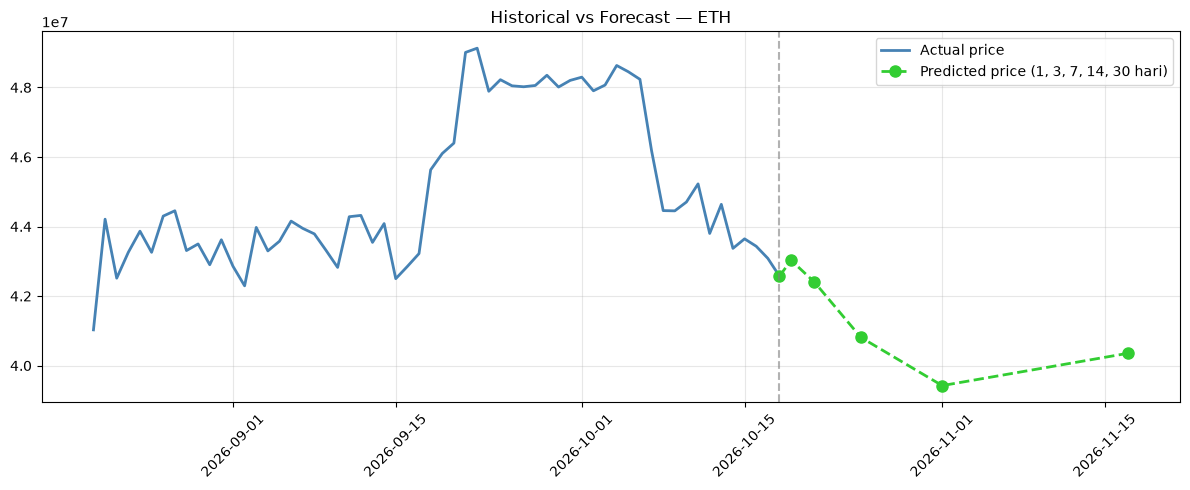

In [15]:
plot_historical_vs_points("ETH", future_eth)

In [16]:
# --- Latih 5 model LSTM untuk SOL, satu per horizon ---
sol_data = processed_data["SOL"]

lstm_models_sol = {}
lstm_target_scalers_sol = {}
lstm_metrics_sol = []

for h in HORIZONS:
    model, metrics, predictions, y_test, target_scaler = train_lstm_for_horizon("SOL", sol_data, h)
    lstm_models_sol[h] = model
    lstm_target_scalers_sol[h] = target_scaler
    lstm_metrics_sol.append(metrics)

metrics_df_sol = pd.DataFrame(lstm_metrics_sol)
metrics_df_sol


=== Horizon 1 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_LSTM_h1.keras, models\target_scaler_SOL_h1.pkl

=== Horizon 3 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_LSTM_h3.keras, models\target_scaler_SOL_h3.pkl

=== Horizon 7 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_LSTM_h7.keras, models\target_scaler_SOL_h7.pkl

=== Horizon 14 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_LSTM_h14.keras, models\target_scaler_SOL_h14.pkl

=== Horizon 30 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_LSTM_h30.keras, models\target_scaler_SOL_h30.pkl


,Horizon,MAE,RMSE,MAPE,R2
0,1d,163727.896368,188936.915874,12.278719,0.229228
1,3d,297089.442308,326592.172841,21.987883,-1.056900
2,7d,372853.697650,403705.969060,27.238123,-1.482633
3,14d,511520.471154,563194.517337,36.823921,-2.742911
4,30d,458769.849359,523067.764887,31.599875,-2.003646


In [17]:
future_sol = predict_future("SOL", lstm_models_sol, lstm_target_scalers_sol)
future_sol

c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


,Horizon,Tanggal Prediksi,Harga Terakhir Diketahui,Prediksi Harga
0,1 hari,2026-10-19,"Rp1,826,000","Rp1,853,016"
1,3 hari,2026-10-21,"Rp1,826,000","Rp1,896,411"
2,7 hari,2026-10-25,"Rp1,826,000","Rp1,989,046"
3,14 hari,2026-11-01,"Rp1,826,000","Rp2,174,171"
4,30 hari,2026-11-17,"Rp1,826,000","Rp2,351,671"


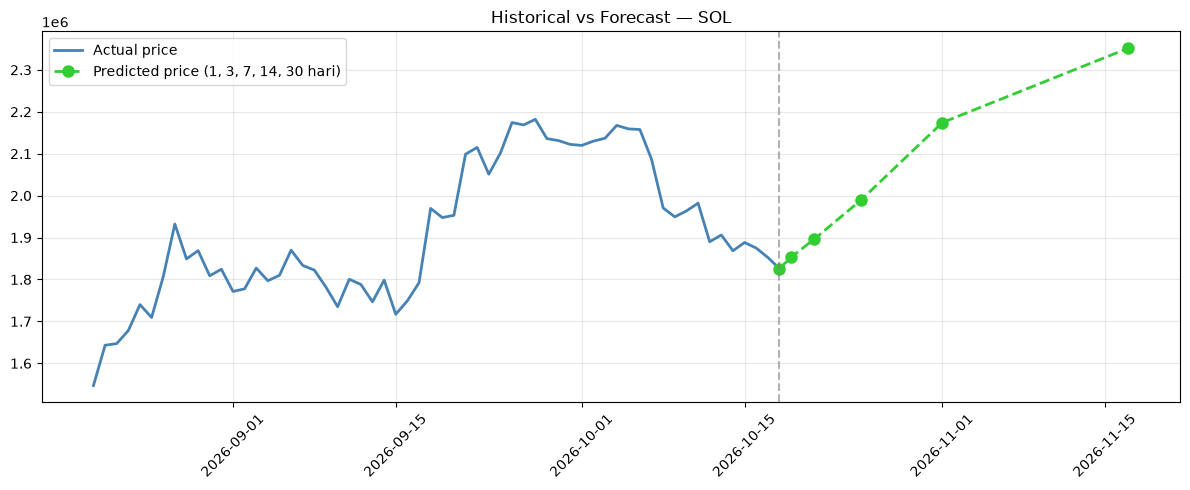

In [18]:
plot_historical_vs_points("SOL", future_sol)

In [19]:
def residual_block(x, filters, kernel_size, dilation_rate):
    """Satu blok TCN: dilated causal convolution + residual connection."""
    prev_x = x

    conv = Conv1D(filters, kernel_size, padding="causal",
                  dilation_rate=dilation_rate, activation="relu")(x)
    conv = Dropout(0.2)(conv)
    conv = Conv1D(filters, kernel_size, padding="causal",
                  dilation_rate=dilation_rate, activation="relu")(conv)

    if prev_x.shape[-1] != filters:
        prev_x = Conv1D(filters, 1, padding="same")(prev_x)

    res = Add()([prev_x, conv])
    res = Activation("relu")(res)
    return res


def build_tcn_model(window_size, n_features, filters=64, kernel_size=3, dilations=(1, 2, 4, 8)):
    inputs = Input(shape=(window_size, n_features))

    x = inputs
    for d in dilations:
        x = residual_block(x, filters, kernel_size, dilation_rate=d)

    x = GlobalAveragePooling1D()(x)
    x = Dense(32, activation="relu")(x)
    outputs = Dense(1)(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.0005), loss="mse")
    return model

In [20]:
def train_tcn_for_horizon(asset, asset_data, horizon, feature_cols=FEATURE_COLS, window_size=WINDOW_SIZE):
    """Latih satu model TCN untuk satu horizon tertentu, kembalikan model + metrik evaluasi."""
    target_col = f"Target_{horizon}d"

    X_train, y_train = create_sequences(asset_data["train"], feature_cols, target_col, window_size)
    X_val, y_val = create_sequences(asset_data["val"], feature_cols, target_col, window_size)
    X_test, y_test = create_sequences(asset_data["test"], feature_cols, target_col, window_size)

    target_scaler = MinMaxScaler(feature_range=(0, 1))
    y_train_scaled = target_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
    y_val_scaled = target_scaler.transform(y_val.reshape(-1, 1)).flatten()

    print(f"\n=== [TCN] Horizon {horizon} hari ===")
    print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

    model = build_tcn_model(window_size, n_features=len(feature_cols))
    early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)

    model.fit(
        X_train, y_train_scaled,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val_scaled),
        callbacks=[early_stop], verbose=0,
    )

    predictions_scaled = model.predict(X_test, verbose=0).flatten()
    predictions = target_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()

    metrics = {
        "Horizon": f"{horizon}d",
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAPE": mean_absolute_percentage_error(y_test, predictions),
        "R2": r2_score(y_test, predictions),
    }

    model_path = os.path.join(SCALER_DIR, f"{asset}_TCN_h{horizon}.keras")
    model.save(model_path)

    target_scaler_path = os.path.join(SCALER_DIR, f"target_scaler_TCN_{asset}_h{horizon}.pkl")
    joblib.dump(target_scaler, target_scaler_path)

    print(f"Tersimpan: {model_path}, {target_scaler_path}")

    return model, metrics, predictions, y_test, target_scaler

In [21]:
tcn_models = {}
tcn_target_scalers = {}
tcn_metrics = []

for h in HORIZONS:
    model, metrics, predictions, y_test, target_scaler = train_tcn_for_horizon("BTC", btc_data, h)
    tcn_models[h] = model
    tcn_target_scalers[h] = target_scaler
    tcn_metrics.append(metrics)

metrics_df_tcn = pd.DataFrame(tcn_metrics)
metrics_df_tcn


=== [TCN] Horizon 1 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_TCN_h1.keras, models\target_scaler_TCN_BTC_h1.pkl

=== [TCN] Horizon 3 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_TCN_h3.keras, models\target_scaler_TCN_BTC_h3.pkl

=== [TCN] Horizon 7 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_TCN_h7.keras, models\target_scaler_TCN_BTC_h7.pkl

=== [TCN] Horizon 14 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_TCN_h14.keras, models\target_scaler_TCN_BTC_h14.pkl

=== [TCN] Horizon 30 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\BTC_TCN_h30.keras, models\target_scaler_TCN_BTC_h30.pkl


,Horizon,MAE,RMSE,MAPE,R2
0,1d,4.155159e+07,5.506064e+07,3.414979,0.752658
1,3d,5.480147e+07,7.336885e+07,4.448915,0.593860
2,7d,7.448174e+07,9.700447e+07,5.989437,0.410561
3,14d,9.590427e+07,1.192068e+08,7.867740,0.291036
4,30d,1.180222e+08,1.346896e+08,9.254833,0.266460


c:\Users\migue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


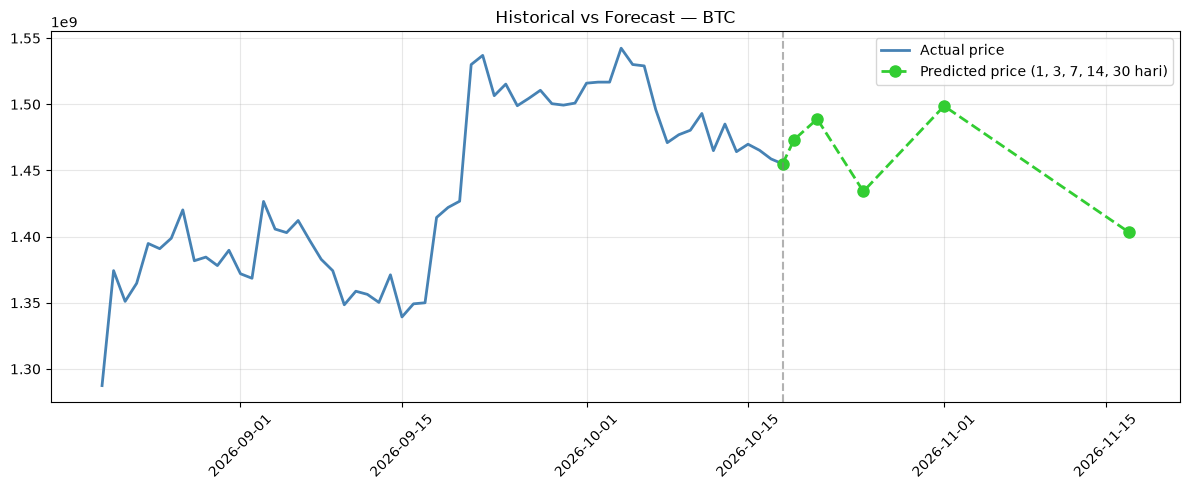

In [22]:
future_btc_tcn = predict_future("BTC", tcn_models, tcn_target_scalers)
plot_historical_vs_points("BTC", future_btc_tcn)

In [24]:
tcn_models_eth, tcn_target_scalers_eth, tcn_metrics_eth = {}, {}, []
for h in HORIZONS:
    model, metrics, predictions, y_test, target_scaler = train_tcn_for_horizon("ETH", eth_data, h)
    tcn_models_eth[h] = model
    tcn_target_scalers_eth[h] = target_scaler
    tcn_metrics_eth.append(metrics)
metrics_df_tcn_eth = pd.DataFrame(tcn_metrics_eth)


=== [TCN] Horizon 1 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_TCN_h1.keras, models\target_scaler_TCN_ETH_h1.pkl

=== [TCN] Horizon 3 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_TCN_h3.keras, models\target_scaler_TCN_ETH_h3.pkl

=== [TCN] Horizon 7 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_TCN_h7.keras, models\target_scaler_TCN_ETH_h7.pkl

=== [TCN] Horizon 14 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_TCN_h14.keras, models\target_scaler_TCN_ETH_h14.pkl

=== [TCN] Horizon 30 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\ETH_TCN_h30.keras, models\target_scaler_TCN_ETH_h30.pkl


In [25]:
tcn_models_sol, tcn_target_scalers_sol, tcn_metrics_sol = {}, {}, []
for h in HORIZONS:
    model, metrics, predictions, y_test, target_scaler = train_tcn_for_horizon("SOL", sol_data, h)
    tcn_models_sol[h] = model
    tcn_target_scalers_sol[h] = target_scaler
    tcn_metrics_sol.append(metrics)
metrics_df_tcn_sol = pd.DataFrame(tcn_metrics_sol)


=== [TCN] Horizon 1 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_TCN_h1.keras, models\target_scaler_TCN_SOL_h1.pkl

=== [TCN] Horizon 3 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_TCN_h3.keras, models\target_scaler_TCN_SOL_h3.pkl

=== [TCN] Horizon 7 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_TCN_h7.keras, models\target_scaler_TCN_SOL_h7.pkl

=== [TCN] Horizon 14 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_TCN_h14.keras, models\target_scaler_TCN_SOL_h14.pkl

=== [TCN] Horizon 30 hari ===
Train: (650, 30, 10) | Val: (116, 30, 10) | Test: (117, 30, 10)
Tersimpan: models\SOL_TCN_h30.keras, models\target_scaler_TCN_SOL_h30.pkl


In [26]:
def compare_lstm_tcn(metrics_lstm_df, metrics_tcn_df, asset_name):
    comparison = metrics_lstm_df.merge(metrics_tcn_df, on="Horizon", suffixes=("_LSTM", "_TCN"))
    comparison.insert(0, "Aset", asset_name)
    return comparison

comparison_all = pd.concat([
    compare_lstm_tcn(metrics_df, metrics_df_tcn, "BTC"),
    compare_lstm_tcn(metrics_df_eth, metrics_df_tcn_eth, "ETH"),
    compare_lstm_tcn(metrics_df_sol, metrics_df_tcn_sol, "SOL"),
], ignore_index=True)

comparison_all

,Aset,Horizon,MAE_LSTM,RMSE_LSTM,MAPE_LSTM,R2_LSTM,MAE_TCN,RMSE_TCN,MAPE_TCN,R2_TCN
0,BTC,1d,2.125694e+07,3.185804e+07,1.742466,0.917196,4.155159e+07,5.506064e+07,3.414979,0.752658
1,BTC,3d,4.061503e+07,6.088504e+07,3.276728,0.720312,5.480147e+07,7.336885e+07,4.448915,0.593860
2,BTC,7d,6.565741e+07,9.351620e+07,5.274715,0.452192,7.448174e+07,9.700447e+07,5.989437,0.410561
3,BTC,14d,8.423512e+07,1.126480e+08,6.500072,0.366904,9.590427e+07,1.192068e+08,7.867740,0.291036
4,BTC,30d,1.226266e+08,1.448472e+08,9.465481,0.151649,1.180222e+08,1.346896e+08,9.254833,0.266460
5,ETH,1d,1.041213e+06,1.287303e+06,3.037962,0.940667,1.214064e+06,1.754844e+06,3.415891,0.889741
6,ETH,3d,1.470357e+06,2.041652e+06,4.256628,0.863247,2.374121e+06,2.957036e+06,6.661311,0.713129
7,ETH,7d,2.324085e+06,3.316388e+06,6.379649,0.692956,3.299839e+06,4.118623e+06,9.643505,0.526441
8,ETH,14d,3.217457e+06,4.289652e+06,8.292374,0.563110,4.021610e+06,4.753171e+06,11.293464,0.463592
9,ETH,30d,4.003394e+06,4.601993e+06,11.033292,0.495810,4.872391e+06,5.578051e+06,13.699187,0.259258


In [27]:
def get_expected_returns(horizon, future_dict, last_prices, assets=["BTC", "ETH", "SOL"]):
    """Konversi harga prediksi -> return, untuk satu horizon, seluruh aset."""
    mu = []
    for asset in assets:
        future_df = future_dict[asset]
        row = future_df[future_df["Horizon"] == f"{horizon} hari"].iloc[0]
        pred_price = float(row["Prediksi Harga"].replace("Rp", "").replace(",", ""))
        last_price = last_prices[asset]
        r = (pred_price - last_price) / last_price
        mu.append(r)
    return np.array(mu)

In [28]:
def get_covariance_matrix(horizon, assets=["BTC", "ETH", "SOL"], lookback_days=90):
    """Hitung matriks covariance dari return historis harian, diskalakan ke horizon h hari."""
    returns = {}
    for asset in assets:
        df = merged_data[asset].sort_values("Tanggal").tail(lookback_days + 1)
        daily_returns = df["Close_indodax"].pct_change().dropna()
        returns[asset] = daily_returns.values[-lookback_days:]

    returns_matrix = np.array([returns[a] for a in assets])
    cov_daily = np.cov(returns_matrix)
    cov_h = cov_daily * horizon  # asumsi return harian independen, diskalakan linear ke horizon
    return cov_h

In [29]:
from scipy.optimize import minimize

BI_RATE_ANNUAL = 0.0575  # sesuaikan dengan Tabel 3.2 di proposal Anda
RF_DAILY = BI_RATE_ANNUAL / 365

def optimize_markowitz(mu, cov, rf, assets=["BTC", "ETH", "SOL"], min_weight=0.2):
    """Optimasi bobot portofolio: maksimalkan Sharpe Ratio, dengan Σw=1 dan w>=min_weight."""
    n = len(mu)

    def neg_sharpe(w):
        port_return = w @ mu
        port_std = np.sqrt(w @ cov @ w)
        return -(port_return - rf) / port_std

    constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}
    bounds = [(min_weight, 1) for _ in range(n)]  # <-- batas bawah diubah
    w0 = np.array([1 / n] * n)

    result = minimize(neg_sharpe, w0, method="SLSQP", bounds=bounds, constraints=constraints)
    weights = result.x
    port_return = weights @ mu
    port_std = np.sqrt(weights @ cov @ weights)
    sharpe = (port_return - rf) / port_std

    return {
        "weights": dict(zip(assets, weights)),
        "expected_return": port_return,
        "risk": port_std,
        "sharpe_ratio": sharpe,
    }

In [30]:
last_prices = {
    "BTC": merged_data["BTC"]["Close_indodax"].iloc[-1],
    "ETH": merged_data["ETH"]["Close_indodax"].iloc[-1],
    "SOL": merged_data["SOL"]["Close_indodax"].iloc[-1],
}
future_dict = {"BTC": future_btc, "ETH": future_eth, "SOL": future_sol}

markowitz_results = []
for h in HORIZONS:
    mu = get_expected_returns(h, future_dict, last_prices)
    cov = get_covariance_matrix(h)
    rf_h = RF_DAILY * h

    result = optimize_markowitz(mu, cov, rf_h)
    markowitz_results.append({
        "Horizon": f"{h}d",
        "Bobot_BTC": f"{result['weights']['BTC']:.1%}",
        "Bobot_ETH": f"{result['weights']['ETH']:.1%}",
        "Bobot_SOL": f"{result['weights']['SOL']:.1%}",
        "Expected_Return": f"{result['expected_return']:.2%}",
        "Risk": f"{result['risk']:.2%}",
        "Sharpe_Ratio": f"{result['sharpe_ratio']:.3f}",
    })

markowitz_df = pd.DataFrame(markowitz_results)
markowitz_df

,Horizon,Bobot_BTC,Bobot_ETH,Bobot_SOL,Expected_Return,Risk,Sharpe_Ratio
0,1d,20.0%,20.0%,60.0%,0.96%,2.44%,0.386
1,3d,20.0%,20.0%,60.0%,2.18%,4.23%,0.503
2,7d,20.0%,20.0%,60.0%,4.53%,6.46%,0.684
3,14d,20.0%,20.0%,60.0%,9.50%,9.14%,1.016
4,30d,20.0%,20.0%,60.0%,16.31%,13.37%,1.184


In [31]:
expected_returns_table = []

for h in HORIZONS:
    mu = get_expected_returns(h, future_dict, last_prices)
    expected_returns_table.append({
        "Horizon": f"{h}d",
        "Expected_Return_BTC": f"{mu[0]:.2%}",
        "Expected_Return_ETH": f"{mu[1]:.2%}",
        "Expected_Return_SOL": f"{mu[2]:.2%}",
    })

expected_returns_df = pd.DataFrame(expected_returns_table)
expected_returns_df

,Horizon,Expected_Return_BTC,Expected_Return_ETH,Expected_Return_SOL
0,1d,-0.72%,1.07%,1.48%
1,3d,-0.30%,-0.40%,3.86%
2,7d,-0.01%,-4.14%,8.93%
3,14d,-2.29%,-7.39%,19.07%
4,30d,0.40%,-5.21%,28.79%
